# Next-Best-Offer (NBO) & ARPU Upsell Engine — Airtel Thanks App
### Calibrated multi-class LightGBM  →  expected incremental ARPU  →  constrained Integer Linear Program

**What this notebook does, end to end**

| # | Stage | Tool / maths |
|---|-------|--------------|
| 1 | Frame the problem as *predict-then-optimize* | decision theory, expected value |
| 2 | Load real telecom data (**Cell2Cell**) and map it to Airtel-style features | data engineering |
| 3 | Domain feature engineering (quota exhaustion velocity, off-peak/weekend ratio, device tier, day-of-month periodicity) | percentile ranks, ratios, circular encoding |
| 4 | Build outcome labels $Y\in\{0,\dots,4\}$ with a **known** ground-truth probability model | multinomial logit (softmax) |
| 5 | Train / early-stop / calibrate / test split | leakage-free evaluation |
| 6 | Multi-class **LightGBM** | softmax + cross-entropy + Newton boosting |
| 7 | **Isotonic calibration** (PAVA) | monotone regression, Brier score, ECE |
| 8 | Expected incremental ARPU matrix $v_{ik}$ | expectation |
| 9 | **ILP** (SciPy `milp`/HiGHS) with budget, contact-fatigue, sticker-shock, partner-quota constraints | integer programming, LP relaxation |
| 10 | Scalable **Lagrangian** solver (millions of users) | duality |
| 11 | Baselines + evaluation against *true* probabilities | Incremental ARPU, Brier, Precision@K |

> **Honesty note on data.** Cell2Cell is a *real* telecom customer table (usage, revenue, handset, churn) but it has **no offer-response labels** and no Airtel-specific columns. So: real columns are used wherever possible (revenue→ARPU, minutes, overage, handset price, …); the few app-level signals that don't exist in it (add-on count, days-to-expiry, contact fatigue, recharge day) are **simulated and clearly marked**; the *purchase outcome* is generated from a known logit model. That is deliberate — it lets us check calibration against the **true** probabilities, which is impossible with real data. With production logs you would replace Section 4 by real labels and everything else stays identical.

In [23]:
import os, glob, zipfile, io, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.optimize import milp, LinearConstraint, Bounds
from sklearn.model_selection import train_test_split
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import log_loss

try:
    import lightgbm as lgb
except ImportError:                       # auto-install on a fresh machine / Colab
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lightgbm"])
    import lightgbm as lgb

# scikit-learn >=1.6 removed cv="prefit" in favour of FrozenEstimator; support both.
try:
    from sklearn.frozen import FrozenEstimator
    def make_calibrator(est, method="isotonic"):
        return CalibratedClassifierCV(FrozenEstimator(est), method=method)
except ImportError:
    def make_calibrator(est, method="isotonic"):
        return CalibratedClassifierCV(est, method=method, cv="prefit")

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
SEED = 42
rng = np.random.default_rng(SEED)
print("lightgbm", lgb.__version__)

lightgbm 4.6.0


## 1. Problem framing — why naive recommenders fail in telecom

Netflix-style collaborative filtering ranks items by *"will they like it?"*. Telecom NBO must rank by **expected money, net of cost, under business rules**:

* Pushing the ₹999 postpaid bundle to a ₹299 prepaid user has almost zero conversion (**sticker shock**) and burns a notification slot.
* Too many pushes → **contact fatigue** (opt-outs, uninstalls).
* Discounts/cashback cost real money → a **daily promo budget** $B$.
* Partner contracts (e.g. Xstream OTT) impose **minimum volumes** $Q$.

Hence a **two-stage predict-then-optimize** system:

1. **Predict**: calibrated $p_{ik}=P(Y_i=k\mid \mathbf x_i)$, with $k=0$ no purchase, $k=1$ lateral renewal (same ARPU), $k=2$ data booster, $k=3$ OTT bundle, $k=4$ postpaid/high tier.
2. **Prescribe**: choose at most one offer per user to maximise total expected incremental ARPU subject to constraints.

**Why *calibrated* probabilities, not just a good ranking?** The optimiser *multiplies* $p_{ik}$ by rupees and *adds* across users and compares to a budget. Ranking metrics (AUC) are blind to the *level* of $p$; but a 5 % over-estimate on a ₹300 lift is a phantom ₹15 per user, and over a million users the budget constraint is silently violated. Calibration ($P(Y=k\mid \hat p=q)=q$) is what makes sums of probabilities equal sums of conversions.

## 2. Data — real Cell2Cell telecom table (auto-detected)

The loader looks for `cell2celltrain.csv` (or a `.zip` containing it) next to the notebook, in `data/`, or in `/mnt/user-data/uploads`; in Google Colab it will prompt for an upload. If nothing is found it falls back to a *synthetic look-alike* so the notebook **never crashes** (it prints which source was used).

How Cell2Cell columns are re-purposed for the Airtel setting:

| Airtel concept | Cell2Cell column(s) used |
|---|---|
| current 28-day ARPU | `MonthlyRevenue` (rescaled to ₹, rank-preserving) |
| quota exhaustion velocity | percentile of `OverageMinutes` and `MonthlyMinutes` (heavy use ⇒ cap hit earlier) |
| weekend / off-peak streaming ratio | `OffPeakCallsInOut / PeakCallsInOut` |
| device tier / 5G proxy | `HandsetPrice`, `HandsetWebCapable` |
| price-elasticity proxy | `RespondsToMailOffers`, overage (⇒ simulated add-on count) |
| tenure, equipment age, care calls, drops | `MonthsInService`, `CurrentEquipmentDays`, `CustomerCareCalls`, `DroppedCalls` |
| **simulated** app signals | `days_to_expiry`, `contact_fatigue_7d`, recharge day-of-month, `addon_count_60d` |

In [24]:
NEEDED = "cell2celltrain.csv"

def make_fake_cell2cell(n=40000, seed=0):
    # Fallback ONLY: statistical look-alike with the same column names.
    r = np.random.default_rng(seed)
    mins = r.gamma(2.0, 260, n)
    over = r.gamma(1.0, 60, n) * (r.random(n) < 0.6)
    rev = np.clip(25 + 0.045 * mins + 0.25 * over + r.normal(0, 12, n), 5, None)
    return pd.DataFrame({
        "MonthlyRevenue": rev, "MonthlyMinutes": mins, "OverageMinutes": over,
        "PeakCallsInOut": r.gamma(2.0, 60, n), "OffPeakCallsInOut": r.gamma(2.0, 25, n),
        "HandsetPrice": r.choice(["Unknown", "30", "60", "80", "130", "150", "200"], n,
                                 p=[.55, .15, .06, .05, .06, .08, .05]),
        "HandsetWebCapable": r.choice(["Yes", "No"], n, p=[.8, .2]),
        "CurrentEquipmentDays": r.gamma(3, 125, n), "MonthsInService": r.integers(1, 60, n),
        "CustomerCareCalls": r.poisson(1.8, n), "DroppedCalls": r.gamma(2, 3, n),
        "RespondsToMailOffers": r.choice(["Yes", "No"], n, p=[.3, .7]),
    })

def load_cell2cell():
    for p in [NEEDED, f"data/{NEEDED}", f"/mnt/user-data/uploads/{NEEDED}"]:
        if os.path.exists(p):
            return pd.read_csv(p), f"csv file: {p}"
    zips = glob.glob("*.zip") + glob.glob("data/*.zip") + glob.glob("/mnt/user-data/uploads/*.zip")
    for z in zips:
        try:
            with zipfile.ZipFile(z) as zf:
                for name in zf.namelist():
                    if os.path.basename(name) == NEEDED:
                        with zf.open(name) as fh:
                            return pd.read_csv(io.BytesIO(fh.read())), f"zip: {z}/{name}"
        except zipfile.BadZipFile:
            continue
    try:                                            # Google Colab upload (interactive)
        from google.colab import files
        print("Upload cell2celltrain.csv or the .zip that contains it ...")
        up = files.upload()
        for name, content in up.items():
            if name.endswith(".csv"):
                return pd.read_csv(io.BytesIO(content)), f"colab upload: {name}"
            if name.endswith(".zip"):
                with zipfile.ZipFile(io.BytesIO(content)) as zf:
                    for n_ in zf.namelist():
                        if os.path.basename(n_) == NEEDED:
                            return pd.read_csv(io.BytesIO(zf.read(n_))), f"colab upload: {name}/{n_}"
    except Exception:
        pass
    return make_fake_cell2cell(), "SYNTHETIC FALLBACK (Cell2Cell file not found)"

raw, source = load_cell2cell()
print("Data source :", source)
print("Shape       :", raw.shape)
raw[["MonthlyRevenue", "MonthlyMinutes", "OverageMinutes", "PeakCallsInOut", "OffPeakCallsInOut",
     "HandsetPrice", "HandsetWebCapable", "CurrentEquipmentDays", "MonthsInService"]].head()

Data source : zip: archive (2).zip/cell2celltrain.csv
Shape       : (51047, 58)


,MonthlyRevenue,MonthlyMinutes,OverageMinutes,PeakCallsInOut,OffPeakCallsInOut,HandsetPrice,HandsetWebCapable,CurrentEquipmentDays,MonthsInService
0,24.00,219.0,0.0,58.0,24.0,30,Yes,361.0,61
1,16.99,10.0,0.0,5.0,1.0,30,No,1504.0,58
2,38.00,8.0,0.0,1.3,3.7,Unknown,No,1812.0,60
3,82.28,1312.0,0.0,555.7,303.7,10,Yes,458.0,59
4,17.14,0.0,0.0,0.0,0.0,10,No,852.0,53


## 3. Feature engineering (with the maths)

**(a) ARPU rescaling.** Cell2Cell revenue is in US\$. We use a rank-preserving linear rescale to Indian prepaid price points  
$$\text{arpu}_i=\operatorname{clip}\!\Big(299\cdot\frac{\text{MonthlyRevenue}_i}{\text{median}(\text{MonthlyRevenue})},\;149,\;999\Big).$$

**(b) Percentile rank** $\;\text{pct}(x_i)=\frac{\#\{j:x_j\le x_i\}}{N}\in(0,1]$ — scale-free, robust to the heavy tails of telecom usage.

**(c) Quota-exhaustion velocity.** Real definition: hours after midnight until the user has consumed 90 % of the daily cap (small ⇒ strong data-booster signal). Proxy from real columns:  
$$\text{intensity}_i=0.6\,\text{pct}(\text{Overage}_i)+0.4\,\text{pct}(\text{Minutes}_i),\qquad \text{quota\_exhaust\_hrs}_i=\operatorname{clip}(23-19\,\text{intensity}_i+\varepsilon_i,\,1,\,24),\;\varepsilon\sim\mathcal N(0,1.5^2).$$

**(d) Off-peak (weekend-style streaming) ratio** $\dfrac{\text{OffPeak}}{\text{Peak}+1}$ — the $+1$ avoids division by zero (same role as $\epsilon$ in $\frac{\text{Data}_{Sat\text{-}Sun}}{\text{Data}_{Mon\text{-}Fri}+\epsilon}$). High ⇒ OTT candidate.

**(e) Device tier / 5G proxy.** Numeric handset price (`Unknown`→median) and `is_5g_proxy = price ≥ 130 ∧ web-capable`.

**(f) Recharge day-of-month periodicity — circular encoding.** Day 30 and day 1 are neighbours, but numerically far. Map the day $d$ onto a circle:  
$$\big(\sin\tfrac{2\pi d}{30},\;\cos\tfrac{2\pi d}{30}\big).$$ Trees can then split on "start-of-month" without a discontinuity (salaried users recharge on days 1–7).

**(g) Simulated app signals:** `days_to_expiry`, `contact_fatigue_7d` (# promo pushes in last 7 days), `addon_count_60d` (₹19/₹29 booster purchases — price-elasticity proxy).

In [25]:
df = raw.copy()
num_cols = ["MonthlyRevenue", "MonthlyMinutes", "OverageMinutes", "PeakCallsInOut", "OffPeakCallsInOut",
            "CustomerCareCalls", "DroppedCalls", "CurrentEquipmentDays", "MonthsInService"]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    df[c] = df[c].fillna(df[c].median())
df = df[df["MonthlyRevenue"] > 0].reset_index(drop=True)      # drop non-positive revenue rows
n = len(df)
pct = lambda s: s.rank(pct=True)
r = np.random.default_rng(SEED)                                # separate stream for feature simulation

F = pd.DataFrame(index=df.index)
# (a) ARPU in rupees
F["current_arpu"] = np.clip(np.round(299 * df["MonthlyRevenue"] / df["MonthlyRevenue"].median()), 149, 999)
# (c) quota exhaustion velocity (hours; lower = faster)
intensity = 0.6 * pct(df["OverageMinutes"]) + 0.4 * pct(df["MonthlyMinutes"])
F["quota_exhaust_hrs"] = np.clip(23 - 19 * intensity + r.normal(0, 1.5, n), 1, 24)
# (d) off-peak / weekend-style ratio
F["offpeak_ratio"] = np.clip(df["OffPeakCallsInOut"] / (df["PeakCallsInOut"] + 1), 0, 5)
# (e) device tier proxies
hp = pd.to_numeric(df["HandsetPrice"].replace("Unknown", np.nan), errors="coerce")
F["handset_price"] = hp.fillna(hp.median())
F["is_5g_proxy"] = ((F["handset_price"] >= 130) & (df["HandsetWebCapable"] == "Yes")).astype(int)
# plain behavioural columns
F["equip_age_days"] = df["CurrentEquipmentDays"]
F["tenure_months"] = df["MonthsInService"]
F["monthly_minutes"] = df["MonthlyMinutes"]
F["overage_minutes"] = df["OverageMinutes"]
F["care_calls"] = df["CustomerCareCalls"]
F["dropped_calls"] = df["DroppedCalls"]
# (g) SIMULATED app signals
responds = (df.get("RespondsToMailOffers", pd.Series("No", index=df.index)) == "Yes").astype(float)
lam_addon = 0.3 + 1.7 * pct(df["OverageMinutes"]) + 0.6 * responds
F["addon_count_60d"] = r.poisson(lam_addon)
F["days_to_expiry"] = r.integers(0, 15, n)
F["contact_fatigue_7d"] = np.minimum(r.poisson(1.3, n), 5)
# (f) recharge day-of-month, circular encoding (50 % "salaried" users recharge on days 1-7)
dom = np.where(r.random(n) < 0.5, r.integers(1, 8, n), r.integers(1, 31, n))
F["dom_sin"] = np.sin(2 * np.pi * dom / 30)
F["dom_cos"] = np.cos(2 * np.pi * dom / 30)

FEATS = list(F.columns)
print(f"{n:,} users, {len(FEATS)} features")
print("5G-proxy share: %.1f%% | users blocked by fatigue (>=5 pushes): %.1f%%"
      % (100 * F.is_5g_proxy.mean(), 100 * (F.contact_fatigue_7d >= 5).mean()))
F.describe().T[["mean", "std", "min", "50%", "max"]].round(2)

51,038 users, 16 features
5G-proxy share: 14.7% | users blocked by fatigue (>=5 pushes): 1.1%


,mean,std,min,50%,max
current_arpu,355.73,205.38,149.00,299.00,999.00
quota_exhaust_hrs,13.50,4.96,1.00,13.92,24.00
offpeak_ratio,0.72,0.63,0.00,0.57,5.00
handset_price,69.62,41.21,10.00,60.00,500.00
is_5g_proxy,0.15,0.35,0.00,0.00,1.00
equip_age_days,380.50,253.74,-5.00,329.00,1812.00
tenure_months,18.75,9.80,6.00,16.00,61.00
monthly_minutes,525.25,529.14,0.00,366.00,7359.00
overage_minutes,39.92,96.47,0.00,3.00,4321.00
care_calls,1.87,5.10,0.00,0.00,327.30


## 4. Outcome labels — a known multinomial-logit "world"

Classes: **0** no purchase / churn-risk · **1** lateral renewal (same tier) · **2** data booster (+₹80) · **3** Xstream OTT bundle (+₹160) · **4** postpaid / high-tier (+₹300).

Each user has latent utilities $u_{ik}=\mathbf w_k^{\top}\mathbf x_i+\eta_{ik}$ ($\eta\sim\mathcal N(0,0.3^2)$ unobserved noise) and the **true** purchase distribution is the **softmax**
$$P_{\text{true}}(Y_i=k)=\frac{e^{u_{ik}}}{\sum_{j=0}^{4}e^{u_{ij}}},\qquad Y_i\sim\text{Categorical}(P_{\text{true}}(\cdot)).$$
We keep $P_{\text{true}}$ — the model never sees it — so we can later measure true calibration and the *true* value of every allocation. The business logic baked in: fast quota exhaustion → data booster; high off-peak ratio + 5G → OTT; high ARPU + 5G → postpaid; contact fatigue lowers every upsell and raises "no purchase".

*(In production, this section is replaced by real purchase labels from the outcome window $[t,t+7d]$, with features computed from $[t-30d,t]$ only.)*

In [26]:
z = lambda s: (s - s.mean()) / s.std()
rl = np.random.default_rng(SEED + 1)

fat, dte, addon = F["contact_fatigue_7d"], F["days_to_expiry"], F["addon_count_60d"]
g5 = F["is_5g_proxy"]
u0 = 0.3 + 0.35 * fat + 0.10 * dte
u1 = 1.4 - 0.06 * dte + 0.20 * z(F["tenure_months"])
u2 = -0.6 + 1.1 * (14 - F["quota_exhaust_hrs"]) / 5 + 0.30 * addon - 0.25 * fat
u3 = -1.3 + 0.9 * z(F["offpeak_ratio"]) + 0.6 * g5 + 0.4 * z(F["monthly_minutes"]) - 0.2 * fat
u4 = -2.6 + 0.9 * z(F["current_arpu"]) + 0.9 * g5 + 0.2 * addon - 0.15 * fat
U = np.column_stack([u0, u1, u2, u3, u4]) + rl.normal(0, 0.3, (n, 5))
U = U - U.max(axis=1, keepdims=True)                       # numerical stability of softmax
P_true = np.exp(U); P_true /= P_true.sum(axis=1, keepdims=True)
cum = P_true.cumsum(axis=1)
y = np.minimum((rl.random(n)[:, None] > cum).sum(axis=1), 4)

CLASS_NAMES = ["No purchase", "Lateral renewal", "Data booster", "Xstream OTT", "Postpaid/high-tier"]
print(pd.DataFrame({"share": np.bincount(y, minlength=5) / n,
                    "mean_true_p": P_true.mean(axis=0)}, index=CLASS_NAMES).round(4))

                     share  mean_true_p
No purchase         0.4853       0.4865
Lateral renewal     0.3182       0.3184
Data booster        0.1287       0.1283
Xstream OTT         0.0498       0.0486
Postpaid/high-tier  0.0180       0.0181


## 5. Four-way split (no leakage)

| Fold | Share | Used for |
|---|---|---|
| Train | 60 % | fit trees |
| Validation | 10 % | **early stopping** (choose number of boosting rounds) |
| Calibration | 15 % | fit isotonic maps — *never* the data the trees were trained on, otherwise the trees look over-confident and isotonic learns the wrong correction |
| Test | 15 % | final report **and** the optimisation cohort |

We stratify on $y$ so rare classes (postpaid) appear in every fold. With real logs use a **chronological** (out-of-time) split instead: train on the earliest weeks, calibrate on the next, test on the most recent — this guards against seasonality/drift leakage.

In [27]:
idx = np.arange(n)
idx_rest, idx_test = train_test_split(idx, test_size=0.15, stratify=y, random_state=SEED)
idx_rest, idx_cal = train_test_split(idx_rest, test_size=0.15 / 0.85, stratify=y[idx_rest], random_state=SEED)
idx_tr, idx_val = train_test_split(idx_rest, test_size=0.10 / 0.70, stratify=y[idx_rest], random_state=SEED)

X_tr, y_tr = F.iloc[idx_tr], y[idx_tr]
X_val, y_val = F.iloc[idx_val], y[idx_val]
X_cal, y_cal = F.iloc[idx_cal], y[idx_cal]
X_test, y_test = F.iloc[idx_test].reset_index(drop=True), y[idx_test]
P_true_test = P_true[idx_test]
print({k: len(v) for k, v in dict(train=idx_tr, val=idx_val, cal=idx_cal, test=idx_test).items()})

{'train': 30622, 'val': 5104, 'cal': 7656, 'test': 7656}


## 6. The algorithm: multi-class gradient-boosted trees (LightGBM)

### 6.1 Softmax model and loss
For $K{+}1=5$ classes the model keeps one additive score (logit) per class, $z_{ik}=F_k(\mathbf x_i)$:
$$q_{ik}=\frac{e^{z_{ik}}}{\sum_j e^{z_{ij}}},\qquad \mathcal L=-\frac1N\sum_i\sum_k \mathbb 1[y_i=k]\log q_{ik}\quad(\text{cross-entropy / log-loss}).$$
Gradient and Hessian w.r.t. the logit (derived from $\partial q_{ik}/\partial z_{ik}=q_{ik}(1-q_{ik})$):
$$g_{ik}=q_{ik}-\mathbb 1[y_i=k],\qquad h_{ik}=q_{ik}(1-q_{ik}).$$

### 6.2 Boosting (Newton / second-order)
Start from $F_k^{(0)}=$ log class prior. At round $m$, for each class a small regression tree $f_k^{(m)}$ is fit to reduce the loss. A second-order Taylor expansion of the regularised objective around the current scores gives, for a tree with leaves $j$ holding sample sets $I_j$ and weights $w_j$:
$$\tilde{\mathcal L}\approx\sum_j\Big[G_jw_j+\tfrac12(H_j+\lambda)w_j^2\Big]+\gamma T,\quad G_j=\sum_{i\in I_j}g_i,\;H_j=\sum_{i\in I_j}h_i.$$
Minimising over $w_j$:
$$\boxed{w_j^*=-\frac{G_j}{H_j+\lambda}},\qquad \text{leaf score}=-\tfrac12\sum_j\frac{G_j^2}{H_j+\lambda}+\gamma T.$$
A candidate split is scored by its **gain**
$$\text{Gain}=\tfrac12\Big[\frac{G_L^2}{H_L+\lambda}+\frac{G_R^2}{H_R+\lambda}-\frac{(G_L+G_R)^2}{H_L+H_R+\lambda}\Big]-\gamma .$$
The update is shrunk by the learning rate $\eta$: $F_k^{(m)}=F_k^{(m-1)}+\eta f_k^{(m)}$. Hyper-parameters map directly: `learning_rate`$=\eta$, `reg_lambda`$=\lambda$, `min_split_gain`$=\gamma$, `num_leaves`$=T$ cap, `min_child_samples` (min leaf size), `subsample`/`colsample_bytree` (stochastic boosting).

### 6.3 What makes LightGBM different from vanilla GBDT
* **Histogram binning** – features are bucketed into ≤255 bins; split search is $O(\#\text{bins})$ not $O(N)$.
* **Leaf-wise (best-first) growth** – always split the leaf with largest gain (deeper, more accurate than level-wise; controlled by `num_leaves`, `min_child_samples`).
* **GOSS** (gradient-based one-side sampling) and **EFB** (exclusive feature bundling) for speed on large/sparse data.
* **Early stopping** – stop adding rounds when validation log-loss hasn't improved for 50 rounds.

*CatBoost* alternative: symmetric (oblivious) trees + ordered target statistics — strong with many categorical features; the rest of this pipeline is unchanged.

### 6.4 Sanity check of $g,h$ (numerical)

In [28]:
# Verify g = q - y and h = q(1-q) against finite differences of the cross-entropy.
rc = np.random.default_rng(0)
zl = rc.normal(size=5); yk = 2
softmax = lambda v: np.exp(v - v.max()) / np.exp(v - v.max()).sum()
ce = lambda v: -np.log(softmax(v)[yk])
q = softmax(zl); eps = 1e-5
g_num = np.array([(ce(zl + eps * np.eye(5)[k]) - ce(zl - eps * np.eye(5)[k])) / (2 * eps) for k in range(5)])
g_an = q - np.eye(5)[yk]
h_num = np.array([(ce(zl + eps * np.eye(5)[k]) - 2 * ce(zl) + ce(zl - eps * np.eye(5)[k])) / eps**2 for k in range(5)])
h_an = q * (1 - q)
print("max |g_num - g_analytic| =", np.abs(g_num - g_an).max())
print("max |h_num - h_analytic| =", np.abs(h_num - h_an).max())

max |g_num - g_analytic| = 1.855834930175604e-11
max |h_num - h_analytic| = 2.212951351762693e-06


best iteration: 68


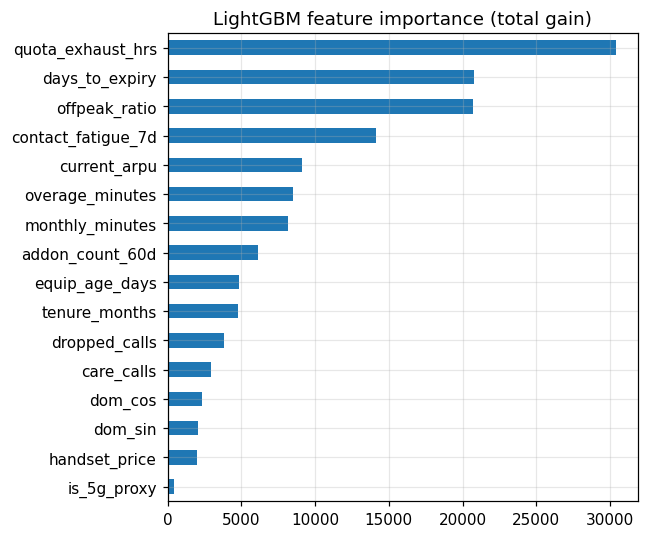

In [29]:
base = lgb.LGBMClassifier(
    objective="multiclass", n_estimators=2000, learning_rate=0.05, num_leaves=31,
    min_child_samples=40, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    reg_lambda=1.0, random_state=SEED, verbose=-1,
)
base.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], eval_metric="multi_logloss",
         callbacks=[lgb.early_stopping(50, verbose=False)])
print("best iteration:", base.best_iteration_)

imp = pd.Series(base.booster_.feature_importance("gain"), index=FEATS).sort_values()
imp.plot.barh(figsize=(6, 5), title="LightGBM feature importance (total gain)")
plt.tight_layout(); plt.show()

## 7. Probability calibration

### 7.1 Why boosted trees are mis-calibrated
They minimise log-loss greedily with shrinkage and early stopping; under class imbalance and finite rounds the scores $\hat q$ are typically too extreme or too flat. **Calibration** means $P(Y=k\mid\hat q_k=q)=q$.

### 7.2 Diagnostics
* **Multi-class Brier score** $\;\text{BS}=\frac1N\sum_i\sum_k(p_{ik}-\mathbb 1[y_i=k])^2$. It decomposes as *reliability − resolution + uncertainty*; calibration shrinks the **reliability** term.
* **Expected Calibration Error** (one-vs-rest, class $k$): bin predictions into $B$ bins, $\;\text{ECE}_k=\sum_{b}\frac{|S_b|}{N}\,\big|\,\overline{y}_{b}-\overline{p}_{b}\big|$.
* **Reliability diagram**: $\overline{p}_b$ (x) vs $\overline{y}_b$ (y); the diagonal is perfect.
* **Calibration-in-the-large**: $\sum_i \hat p_{ik}$ vs $\sum_i y_{ik}$ — this is exactly what the budget constraint consumes.

### 7.3 Isotonic regression and PAVA
For each class $k$ (one-vs-rest) fit a non-decreasing step function $g_k$ on the calibration fold:
$$\min_{g_k}\sum_{i=1}^{M}\big(y_{ik}-g_k(\hat q_{ik})\big)^2\quad\text{s.t. } \hat q_{ik}\le\hat q_{jk}\Rightarrow g_k(\hat q_{ik})\le g_k(\hat q_{jk}).$$
Solved exactly in $O(M)$ (after sorting) by the **Pool-Adjacent-Violators Algorithm**: sweep left→right, and whenever a block's mean is larger than the next block's mean, merge them into one block with the weighted mean. Because the $g_k$ don't sum to 1, finish with **row normalisation**
$$p_{ik}=\frac{g_k(\hat q_{ik})}{\sum_{j}g_j(\hat q_{ij})}$$
(this is what `CalibratedClassifierCV` does for multi-class). Isotonic is non-parametric, so it needs a few thousand calibration rows; with little data prefer Platt (`method="sigmoid"`), which fits $\sigma(a\hat q+b)$ — compared below.

First, PAVA from scratch, verified against scikit-learn:

In [30]:
def pava(y_sorted, w=None):
    # Pool Adjacent Violators: least-squares non-decreasing fit to y_sorted (ordered by x).
    y_sorted = np.asarray(y_sorted, float)
    w = np.ones_like(y_sorted) if w is None else np.asarray(w, float)
    vals, wts, cnt = [], [], []
    for yi, wi in zip(y_sorted, w):
        vals.append(yi); wts.append(wi); cnt.append(1)
        while len(vals) > 1 and vals[-2] > vals[-1]:            # violation -> pool the two blocks
            v2, w2, c2 = vals.pop(), wts.pop(), cnt.pop()
            v1, w1, c1 = vals.pop(), wts.pop(), cnt.pop()
            wn = w1 + w2
            vals.append((v1 * w1 + v2 * w2) / wn); wts.append(wn); cnt.append(c1 + c2)
    return np.repeat(vals, cnt)

rt = np.random.default_rng(1)
xs = np.sort(rt.random(500)); ys = (rt.random(500) < xs**2).astype(float)
mine = pava(ys)
ref = IsotonicRegression(increasing=True).fit(xs, ys).predict(xs)
print("PAVA (from scratch) matches sklearn:", np.allclose(mine, ref))

PAVA (from scratch) matches sklearn: True


In [31]:
cal_iso = make_calibrator(base, "isotonic").fit(X_cal, y_cal)
cal_sig = make_calibrator(base, "sigmoid").fit(X_cal, y_cal)

P_raw = base.predict_proba(X_test)
P_iso = cal_iso.predict_proba(X_test)
P_sig = cal_sig.predict_proba(X_test)
Y1h = np.eye(5)[y_test]

def brier(P, Y): return np.mean(np.sum((P - Y) ** 2, axis=1))

def ece_binary(p, yb, bins=15):
    edges = np.linspace(0, 1, bins + 1)
    b = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1)
    tot = 0.0
    for k in range(bins):
        m = b == k
        if m.any():
            tot += m.mean() * abs(yb[m].mean() - p[m].mean())
    return tot

rows = []
for name, P in [("Raw LightGBM", P_raw), ("Platt (sigmoid)", P_sig), ("Isotonic", P_iso)]:
    rows.append({"model": name,
                 "log-loss": log_loss(y_test, P, labels=range(5)),
                 "Brier": brier(P, Y1h),
                 "ECE booster": ece_binary(P[:, 2], Y1h[:, 2]),
                 "ECE OTT": ece_binary(P[:, 3], Y1h[:, 3]),
                 "ECE postpaid": ece_binary(P[:, 4], Y1h[:, 4]),
                 "MAE vs TRUE p (upsell)": np.abs(P[:, 2:] - P_true_test[:, 2:]).mean()})
metrics = pd.DataFrame(rows).set_index("model")
print("Oracle (true-probability) Brier floor:", round(brier(P_true_test, Y1h), 4))
metrics.round(4)

Oracle (true-probability) Brier floor: 0.55


,log-loss,Brier,ECE booster,ECE OTT,ECE postpaid,MAE vs TRUE p (upsell)
model,,,,,,
Raw LightGBM,1.0326,0.5686,0.0083,0.0050,0.0028,0.0195
Platt (sigmoid),1.0450,0.5710,0.0230,0.0061,0.0022,0.0249
Isotonic,1.0628,0.5692,0.0113,0.0062,0.0023,0.0198


Calibration-in-the-large on the TEST fold  (sum of predicted prob  vs  actual count):
                    actual     raw  isotonic
No purchase         3716.0  3717.2    3689.3
Lateral renewal     2436.0  2429.2    2448.8
Data booster         985.0  1001.5    1000.0
Xstream OTT          381.0   376.0     374.9
Postpaid/high-tier   138.0   132.0     143.0


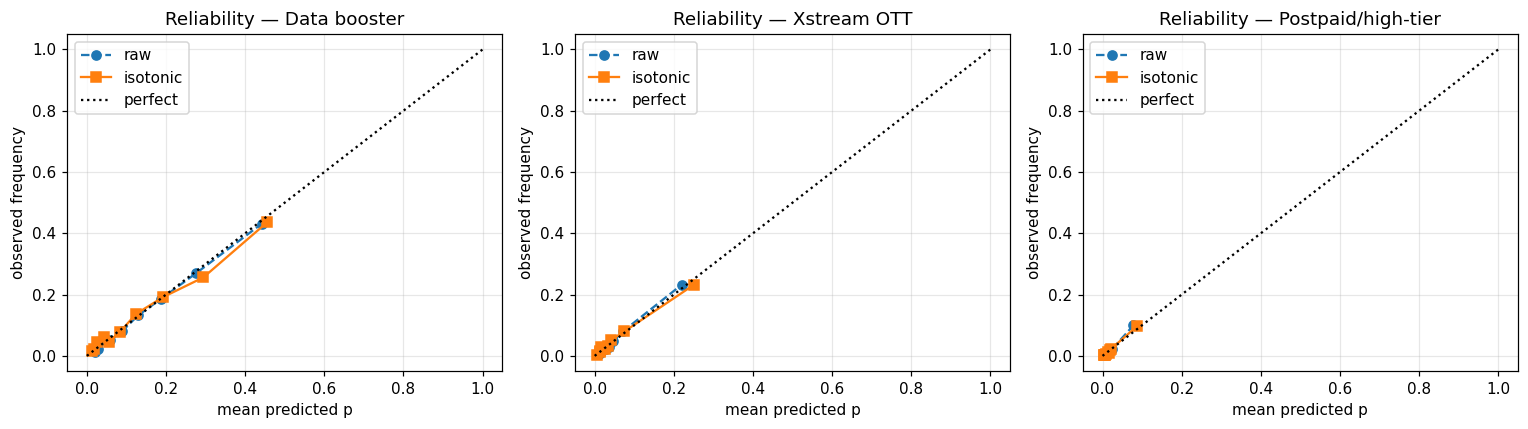

In [32]:
print("Calibration-in-the-large on the TEST fold  (sum of predicted prob  vs  actual count):")
tab = pd.DataFrame({"actual": Y1h.sum(0), "raw": P_raw.sum(0), "isotonic": P_iso.sum(0)}, index=CLASS_NAMES)
print(tab.round(1))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, k in zip(axes, [2, 3, 4]):
    for lab, P, st in [("raw", P_raw, "o--"), ("isotonic", P_iso, "s-")]:
        fp, mp = calibration_curve(Y1h[:, k], P[:, k], n_bins=10, strategy="quantile")
        ax.plot(mp, fp, st, label=lab)
    ax.plot([0, 1], [0, 1], "k:", label="perfect")
    ax.set_title(f"Reliability — {CLASS_NAMES[k]}"); ax.set_xlabel("mean predicted p"); ax.set_ylabel("observed frequency")
    ax.legend()
plt.tight_layout(); plt.show()

### 7.4 Precision@K for upsell targeting
Score each user by $s_i=\max_{k\in\{2,3,4\}}p_{ik}$ (their best upsell propensity); take the top $K$;
$$\text{Precision@}K=\frac1K\sum_{i\in\text{top-}K}\mathbb 1[y_i\ge2],\qquad \text{Lift@}K=\frac{\text{Precision@}K}{\text{base rate}}.$$
Precision@K judges *ranking*; Brier/ECE judge the *probability level* — you need both.

In [33]:
score = P_iso[:, 2:].max(axis=1)
order = np.argsort(-score)
base_rate = np.mean(y_test >= 2)
prec = []
for K in [100, 250, 500, 1000]:
    p_at_k = np.mean(y_test[order[:K]] >= 2)
    prec.append({"K": K, "Precision@K": p_at_k, "base rate": base_rate, "Lift@K": p_at_k / base_rate})
pd.DataFrame(prec).set_index("K").round(3)

,Precision@K,base rate,Lift@K
K,,,
100,0.740,0.196,3.767
250,0.688,0.196,3.502
500,0.610,0.196,3.105
1000,0.536,0.196,2.728


### 7.5 Stress test — calibration matters when the model is *over-confident*
The tuned, early-stopped model above is already close to calibrated here (this simulated world is smooth, and early stopping on log-loss is itself a form of regularisation), so isotonic regression has little to fix — and being a step function it can even add a little noise. **Report that honestly; do not assume calibration always helps.** It becomes essential when a model is over-fitted, which is common in practice (many trees, large learning rate, deep leaves, no early stopping). We build such a model on purpose and use it again in §11 to show what a mis-calibrated predictor does to the optimiser.

In [34]:
over = lgb.LGBMClassifier(objective="multiclass", n_estimators=400, learning_rate=0.15, num_leaves=127,
                          min_child_samples=5, random_state=SEED, verbose=-1)
over.fit(X_tr, y_tr)                                      # no early stopping -> over-confident
cal_over = make_calibrator(over, "isotonic").fit(X_cal, y_cal)
P_over_raw, P_over_iso = over.predict_proba(X_test), cal_over.predict_proba(X_test)
rows = []
for name, P in [("Over-fit GBM (raw)", P_over_raw), ("Over-fit GBM + isotonic", P_over_iso)]:
    rows.append({"model": name, "log-loss": log_loss(y_test, P, labels=range(5)), "Brier": brier(P, Y1h),
                 "ECE booster": ece_binary(P[:, 2], Y1h[:, 2]), "ECE OTT": ece_binary(P[:, 3], Y1h[:, 3]),
                 "ECE postpaid": ece_binary(P[:, 4], Y1h[:, 4]),
                 "MAE vs TRUE p (upsell)": np.abs(P[:, 2:] - P_true_test[:, 2:]).mean()})
pd.DataFrame(rows).set_index("model").round(4)

,log-loss,Brier,ECE booster,ECE OTT,ECE postpaid,MAE vs TRUE p (upsell)
model,,,,,,
Over-fit GBM (raw),1.5888,0.6744,0.0870,0.0429,0.0181,0.0493
Over-fit GBM + isotonic,1.1131,0.5897,0.0132,0.0069,0.0014,0.0312


## 8. From probabilities to money — expected incremental ARPU

Offers that can be pushed are the three **upsells** $k\in\{2,3,4\}$ (a lateral renewal has zero incremental ARPU, so it is not an "offer"; $k=0,1$ is what happens organically). With revenue lift $\Delta_k$ over the user's current plan and a conversion-contingent subsidy $c_k$:
$$v_{ik}=p_{ik}\,(\Delta_k-c_k)-\kappa_k,\qquad \text{expected promo spend } e_{ik}=p_{ik}\,c_k+\kappa_k .$$
Here $\kappa_k$ is a small **per-impression cost** (paid when the offer is *shown*, whether or not the user converts — e.g. free-OTT-trial provisioning, SMS/push cost). It matches the "subsidy paid on impression" term of the general formulation, and it matters mathematically: without it $v_{ik}/e_{ik}=(\Delta_k-c_k)/c_k$ is the *same for every user*, so budget-rationing has no natural ordering and the dual problem in §10 becomes degenerate.

| offer | $\Delta_k$ (₹/28d) | $c_k$ (₹ on conversion) | $\kappa_k$ (₹ per impression) |
|---|---|---|---|
| Data booster | 80 | 15 | 0.5 |
| Xstream OTT | 160 | 35 | 2 |
| Postpaid / high tier | 300 | 60 | 3 |

**Eligibility masks** (variables fixed to 0):
* *Sticker shock*: $\dfrac{\Delta_k}{\text{arpu}_i}>\theta_{\text{shock}}=0.65$ ⇒ offer $k$ not allowed for user $i$ (e.g. +₹300 on a ₹299 plan is +100 %).
* *Contact fatigue*: users with ≥5 pushes in the last 7 days get **no** offer.

In [35]:
LIFT = np.array([80.0, 160.0, 300.0])
COST = np.array([15.0, 35.0, 60.0])
KAPPA = np.array([0.5, 2.0, 3.0])      # per-impression cost
OFFERS = ["Data booster", "Xstream OTT", "Postpaid"]
OTT = 1                      # column index of the OTT offer in the (n x 3) matrices
THETA_SHOCK = 0.65
FATIGUE_MAX = 5

def build_economics(P, X):
    P_off = P[:, 2:5]
    V = P_off * (LIFT - COST) - KAPPA          # expected incremental net ARPU  v_ik
    EC = P_off * COST + KAPPA                  # expected promo spend           e_ik
    shock = (LIFT[None, :] / X["current_arpu"].values[:, None]) > THETA_SHOCK
    fatigued = (X["contact_fatigue_7d"].values >= FATIGUE_MAX)
    elig = (~shock) & (~fatigued[:, None])
    return V, EC, elig

V_cal, EC_cal, elig = build_economics(P_iso, X_test)
V_raw, EC_raw, _ = build_economics(P_raw, X_test)
V_tru, EC_tru, _ = build_economics(P_true_test, X_test)
V_ovr, EC_ovr, _ = build_economics(P_over_raw, X_test)
V_ovc, EC_ovc, _ = build_economics(P_over_iso, X_test)
print("eligible (user,offer) pairs per offer:", dict(zip(OFFERS, elig.sum(0))))
print("users with >=1 eligible offer: %d of %d" % (elig.any(1).sum(), len(elig)))

eligible (user,offer) pairs per offer: {'Data booster': np.int64(7586), 'Xstream OTT': np.int64(4640), 'Postpaid': np.int64(1756)}
users with >=1 eligible offer: 7586 of 7656


### 9.0 Helper first: Lagrangian allocator (explained in full in §10)
It is defined here because we also use it to set a *sensible* quota $Q$ (so the SLA constraint actually binds).

In [36]:
def lagrangian_allocate(V, EC, elig, B, Q, iters=40, lam_hi=200.0, mu_hi=500.0):
    n_users = V.shape[0]
    Vm = np.where(elig, V, -np.inf)
    ar = np.arange(n_users)

    def assign(lam, mu):
        S = Vm - lam * EC
        S[:, OTT] += mu                               # -inf stays -inf for ineligible pairs
        k = S.argmax(1)
        take = S[ar, k] > 0
        return k, take

    def stats(lam, mu):
        k, take = assign(lam, mu)
        spend = EC[ar[take], k[take]].sum()
        ott = int((take & (k == OTT)).sum())
        return spend, ott

    def lam_star(mu):                                  # smallest lam with spend <= B  (spend decreases in lam)
        if stats(0.0, mu)[0] <= B:
            return 0.0
        lo, hi = 0.0, lam_hi
        for _ in range(iters):
            mid = 0.5 * (lo + hi)
            if stats(mid, mu)[0] <= B: hi = mid
            else: lo = mid
        return hi

    if stats(lam_star(0.0), 0.0)[1] >= Q:
        mu = 0.0
    else:
        lo, hi = 0.0, mu_hi
        for _ in range(iters):
            mid = 0.5 * (lo + hi)
            if stats(lam_star(mid), mid)[1] >= Q: hi = mid
            else: lo = mid
        mu = hi
    lam = lam_star(mu)
    k, take = assign(lam, mu)
    Z = np.zeros(V.shape, dtype=int)
    Z[ar[take], k[take]] = 1
    return Z, lam, mu

## 9. Constrained Integer Linear Program

**Decision variables** $z_{ik}\in\{0,1\}$ — user $i$ is shown offer $k$.

$$\max_{z}\;\sum_{i=1}^{N}\sum_{k}v_{ik}\,z_{ik}$$
subject to
$$\begin{aligned}
&\textstyle\sum_k z_{ik}\le 1 &&\forall i &&\text{(one hero banner / contact fatigue)}\\
&\textstyle\sum_{i,k}e_{ik}\,z_{ik}\le B &&&&\text{(daily promo budget)}\\
&\textstyle\sum_i z_{i,\text{OTT}}\ge Q &&&&\text{(partner SLA minimum)}\\
&z_{ik}=0 \;\text{ if } \Delta_k/\text{arpu}_i>\theta_{\text{shock}} \text{ or user fatigued} &&&&\text{(guardrails)}
\end{aligned}$$

**How it is solved.** Drop integrality ⇒ a **linear program** (LP) whose optimum is found by simplex / interior point. The "one-offer-per-user" rows form an assignment-type structure that is totally unimodular; the two *coupling* rows (budget, quota) are what can create fractional vertices, and then **branch-and-bound/cut** (HiGHS inside `scipy.optimize.milp`) restores integrality. In practice the LP relaxation is almost integral (at most ~2 fractional users — one per coupling constraint), so the integrality gap is tiny.

**Implementation details that matter at scale**
* only create variables for *eligible* pairs (shrinks the model),
* build the constraint matrix **sparse** (a dense $N\times 3N$ matrix is $O(N^2)$ memory — fine for 1 000 users, fatal for 10⁶).

In [37]:
def solve_ilp(V, EC, elig, B, Q, time_limit=90):
    # Exact MILP (HiGHS). Returns Z (n x 3 in {0,1}) and solver info.
    n_users, n_off = V.shape
    pairs = np.argwhere(elig)                          # (user, offer) of every eligible variable (row-major)
    nv = len(pairs)
    c = -V[elig]                                       # same row-major order as argwhere -> milp minimises
    u_ids, u_row = np.unique(pairs[:, 0], return_inverse=True)
    A_user = sparse.csr_matrix((np.ones(nv), (u_row, np.arange(nv))), shape=(len(u_ids), nv))
    A_budget = sparse.csr_matrix(EC[elig].reshape(1, -1))
    A_quota = sparse.csr_matrix((pairs[:, 1] == OTT).astype(float).reshape(1, -1))
    A = sparse.vstack([A_user, A_budget, A_quota]).tocsr()
    lb = np.concatenate([np.full(len(u_ids), -np.inf), [-np.inf], [Q]])
    ub = np.concatenate([np.ones(len(u_ids)), [B], [np.inf]])
    t0 = time.time()
    res = milp(c=c, integrality=np.ones(nv), bounds=Bounds(0, 1),
               constraints=LinearConstraint(A, lb, ub),
               options={"time_limit": time_limit, "mip_rel_gap": 1e-3})
    if res.x is None:
        raise RuntimeError(f"MILP failed: status={res.status} {res.message}")
    Z = np.zeros((n_users, n_off), dtype=int)
    Z[pairs[:, 0], pairs[:, 1]] = np.round(res.x).astype(int)
    return Z, {"status": res.message, "seconds": time.time() - t0, "n_vars": nv}

# ---- choose budget B and quota Q so that the constraints actually BIND ----
Vm = np.where(elig, V_cal, -np.inf)
kg = Vm.argmax(1); take = np.isfinite(Vm.max(1)) & (Vm.max(1) > 0)
Z_greedy = np.zeros_like(elig, dtype=int); Z_greedy[np.arange(len(kg))[take], kg[take]] = 1
greedy_spend, greedy_ott = (Z_greedy * EC_cal).sum(), Z_greedy[:, OTT].sum()
B = 0.55 * greedy_spend              # budget = 55 % of what an unconstrained greedy plan would spend
print(f"Greedy (unconstrained) spend = Rs {greedy_spend:,.0f}, OTT offers = {greedy_ott}")
# Partner quota: 5x the OTT volume a budget-only plan would give, so the SLA genuinely binds (it costs value).
Z_b, _, _ = lagrangian_allocate(V_cal, EC_cal, elig, B, 0)
Q = int(5 * max(Z_b[:, OTT].sum(), 10))
print(f"Budget B = Rs {B:,.0f}   Quota Q = {Q}  (budget-only plan gives {Z_b[:, OTT].sum()} OTT offers)")

Z_ilp, info = solve_ilp(V_cal, EC_cal, elig, B, Q)
print(info)
print("ILP offers assigned:", dict(zip(OFFERS, Z_ilp.sum(0))))

Greedy (unconstrained) spend = Rs 25,623, OTT offers = 720
Budget B = Rs 14,092   Quota Q = 140  (budget-only plan gives 28 OTT offers)
{'status': 'Optimization terminated successfully. (HiGHS Status 7: Optimal)', 'seconds': 1.7507133483886719, 'n_vars': 13982}
ILP offers assigned: {'Data booster': np.int64(2193), 'Xstream OTT': np.int64(140), 'Postpaid': np.int64(0)}


In [38]:
def check_constraints(Z, EC, elig, B, Q, label=""):
    ok_one = (Z.sum(1) <= 1).all()
    ok_elig = (Z[~elig] == 0).all()
    spend = (Z * EC).sum()
    print(f"[{label}] one-per-user={ok_one} | guardrails respected={ok_elig} | "
          f"spend {spend:,.0f} <= B {B:,.0f}: {spend <= B + 1e-6} | OTT {Z[:, OTT].sum()} >= Q {Q}: {Z[:, OTT].sum() >= Q}")
check_constraints(Z_ilp, EC_cal, elig, B, Q, "ILP")

[ILP] one-per-user=True | guardrails respected=True | spend 14,090 <= B 14,092: True | OTT 140 >= Q 140: True


## 10. Scaling to millions of users — Lagrangian relaxation

Dualise the two coupling constraints with multipliers $\lambda\ge0$ (budget) and $\mu\ge0$ (quota):
$$\mathcal L(z;\lambda,\mu)=\sum_{i,k}\big(v_{ik}-\lambda e_{ik}+\mu\,\mathbb 1[k=\text{OTT}]\big)z_{ik}+\lambda B-\mu Q .$$
For fixed $(\lambda,\mu)$ the problem **separates by user**: pick $k^*_i=\arg\max_k s_{ik}$ with $s_{ik}=v_{ik}-\lambda e_{ik}+\mu\mathbb 1[k=\text{OTT}]$, and show it only if $s_{ik^*}>0$. This is $O(N)$ and embarrassingly parallel. The dual function $D(\lambda,\mu)=\max_z\mathcal L$ is convex and gives an **upper bound** on the ILP optimum (weak duality) — so you can certify how far from optimal you are. Economically, $\lambda$ is the *shadow price of one rupee of promo budget* and $\mu$ the *shadow price of one OTT slot*.

(This is why §8 includes the per-impression cost $\kappa_k$: it makes $v_{ik}/e_{ik}=\frac{p(\Delta_k-c_k)-\kappa_k}{pc_k+\kappa_k}$ *increase with $p$*, so users are rationed from the most to the least profitable per rupee, and the dual is well-behaved.)

We find the multipliers by nested bisection: for each $\mu$, the smallest $\lambda$ with spend $\le B$; then the smallest $\mu$ with OTT count $\ge Q$.

In [39]:
t0 = time.time()
Z_lag, lam, mu = lagrangian_allocate(V_cal, EC_cal, elig, B, Q)
print(f"Lagrangian: {time.time() - t0:.2f}s | shadow price of Rs1 budget lambda={lam:.3f} | OTT slot mu={mu:.2f}")
check_constraints(Z_lag, EC_cal, elig, B, Q, "Lagrangian")
print("Value  ILP: %.1f | Lagrangian: %.1f | gap %.4f%%" % ((Z_ilp * V_cal).sum(), (Z_lag * V_cal).sum(),
      100 * ((Z_ilp * V_cal).sum() - (Z_lag * V_cal).sum()) / (Z_ilp * V_cal).sum()))

Lagrangian: 0.64s | shadow price of Rs1 budget lambda=3.485 | OTT slot mu=8.17
[Lagrangian] one-per-user=True | guardrails respected=True | spend 14,090 <= B 14,092: True | OTT 140 >= Q 140: True
Value  ILP: 52072.4 | Lagrangian: 52072.4 | gap 0.0000%


In [40]:
# Scalability demo: replicate the test cohort to 1,000,000 users and time the Lagrangian solver.
reps = int(np.ceil(1_000_000 / len(V_cal)))
Vb, ECb, elb = np.tile(V_cal, (reps, 1)), np.tile(EC_cal, (reps, 1)), np.tile(elig, (reps, 1))
t0 = time.time()
Zb, lb_, mb_ = lagrangian_allocate(Vb, ECb, elb, B * reps, Q * reps, iters=22)
print(f"{len(Vb):,} users solved in {time.time() - t0:.1f}s; spend {(Zb * ECb).sum():,.0f} <= {B * reps:,.0f}; "
      f"OTT {Zb[:, OTT].sum():,} >= {Q * reps:,}")
del Vb, ECb, elb, Zb

1,002,936 users solved in 32.0s; spend 1,845,798 <= 1,846,110; OTT 18,340 >= 18,340


## 11. Counterfactual evaluation of strategies

Every strategy is scored with the **true** probabilities $P_{\text{true}}$ (available only because labels were simulated):
$$\text{Incremental ARPU}(Z)=\sum_{i,k}z_{ik}\,p^{\text{true}}_{ik}(\Delta_k-c_k),\qquad \text{Spend}(Z)=\sum_{i,k}z_{ik}\,p^{\text{true}}_{ik}c_k .$$

Strategies compared (all but #3 obey the same budget $B$ *as believed by their own probabilities*):
1. **Random** eligible offer, users picked at random until budget is exhausted.
2. **Rule-based**: fast quota exhaustion → booster; high off-peak ratio → OTT; premium 5G & high ARPU → postpaid; budget enforced in random order.
3. **Greedy unconstrained** $\arg\max_k v_{ik}$ (ignores budget & quota — overspends).
4. **ILP + raw probabilities** of the tuned model.
5. **ILP + isotonic-calibrated probabilities** of the tuned model (the proposed system).
6. **Lagrangian** with calibrated probabilities.
7. **ILP + raw probabilities of the over-fit GBM** (stress test).
8. **ILP + isotonic probabilities of the over-fit GBM** (calibration as a safety net).

Key things to look at: (i) true value, (ii) **true spend vs $B$** — a miscalibrated optimiser looks fine on paper but breaks the budget in reality, (iii) *believed* vs *true* value (phantom gain).

*Caveat:* $p_{ik}$ here is the organic purchase propensity of plan $k$. A production system should model the **uplift** (causal effect of showing the offer), see §12.

In [41]:
rs = np.random.default_rng(7)
n_t = len(X_test)

def truncate_to_budget(Z, EC_believed, B_, order):
    # keep assignments in the given user order until believed spend would exceed B_.
    Z2 = np.zeros_like(Z)
    spent = 0.0
    for i in order:
        if Z[i].any():
            cst = (Z[i] * EC_believed[i]).sum()
            if spent + cst > B_:
                continue
            Z2[i] = Z[i]; spent += cst
    return Z2

# 1. Random
Z_rand = np.zeros((n_t, 3), dtype=int)
for i in range(n_t):
    ks = np.flatnonzero(elig[i])
    if len(ks): Z_rand[i, rs.choice(ks)] = 1
Z_rand = truncate_to_budget(Z_rand, EC_cal, B, rs.permutation(n_t))

# 2. Rule-based
Z_rule = np.zeros((n_t, 3), dtype=int)
q75_off = X_test["offpeak_ratio"].quantile(0.75)
for i in range(n_t):
    x = X_test.iloc[i]
    if x["quota_exhaust_hrs"] < 9 and elig[i, 0]: Z_rule[i, 0] = 1
    elif x["offpeak_ratio"] > q75_off and elig[i, 1]: Z_rule[i, 1] = 1
    elif x["is_5g_proxy"] == 1 and x["current_arpu"] >= 480 and elig[i, 2]: Z_rule[i, 2] = 1
Z_rule = truncate_to_budget(Z_rule, EC_cal, B, rs.permutation(n_t))

# ILPs on other probability sources (same B and Q)
Z_ilp_raw, _ = solve_ilp(V_raw, EC_raw, elig, B, Q)
Z_ilp_ovr, _ = solve_ilp(V_ovr, EC_ovr, elig, B, Q)
Z_ilp_ovc, _ = solve_ilp(V_ovc, EC_ovc, elig, B, Q)

strategies = {
    "1 Random (budget)":        (Z_rand,    V_cal),
    "2 Rule-based (budget)":    (Z_rule,    V_cal),
    "3 Greedy unconstrained":   (Z_greedy,  V_cal),
    "4 ILP + raw probs (tuned)":(Z_ilp_raw, V_raw),
    "5 ILP + isotonic (tuned)": (Z_ilp,     V_cal),
    "6 Lagrangian + isotonic":  (Z_lag,     V_cal),
    "7 ILP + raw (over-fit GBM)":      (Z_ilp_ovr, V_ovr),
    "8 ILP + isotonic (over-fit GBM)": (Z_ilp_ovc, V_ovc),
}
rows = []
for name, (Z, Vbel) in strategies.items():
    true_val, true_spend = (Z * V_tru).sum(), (Z * EC_tru).sum()
    rows.append({"strategy": name, "offers": int(Z.sum()),
                 "believed value": (Z * Vbel).sum(), "TRUE incr. ARPU (Rs)": true_val,
                 "avg/user": true_val / n_t, "TRUE spend": true_spend,
                 "budget B": B, "within budget?": true_spend <= B * 1.0,
                 "ROI (value/spend)": true_val / max(true_spend, 1e-9),
                 "OTT count": int(Z[:, OTT].sum()), "OTT quota met?": Z[:, OTT].sum() >= Q})
res_tab = pd.DataFrame(rows).set_index("strategy")
res_tab.round(2)

,offers,believed value,TRUE incr. ARPU (Rs),avg/user,TRUE spend,budget B,within budget?,ROI (value/spend),OTT count,OTT quota met?
strategy,,,,,,,,,,
1 Random (budget),5028,29509.36,30080.80,3.93,14228.37,14092.45,False,2.11,1316,True
2 Rule-based (budget),2481,45304.02,45129.42,5.89,14061.82,14092.45,True,3.21,664,True
3 Greedy unconstrained,7444,75284.91,73926.63,9.66,25253.20,14092.45,False,2.93,720,True
4 ILP + raw probs (tuned),2574,51615.57,52440.84,6.85,14307.23,14092.45,False,3.67,140,True
5 ILP + isotonic (tuned),2333,52072.35,49918.83,6.52,13571.14,14092.45,True,3.68,140,True
6 Lagrangian + isotonic,2333,52072.35,49918.83,6.52,13571.14,14092.45,True,3.68,140,True
7 ILP + raw (over-fit GBM),2579,51347.45,49414.17,6.45,13609.10,14092.45,True,3.63,140,True
8 ILP + isotonic (over-fit GBM),3035,50452.56,52889.67,6.91,14653.58,14092.45,False,3.61,140,True


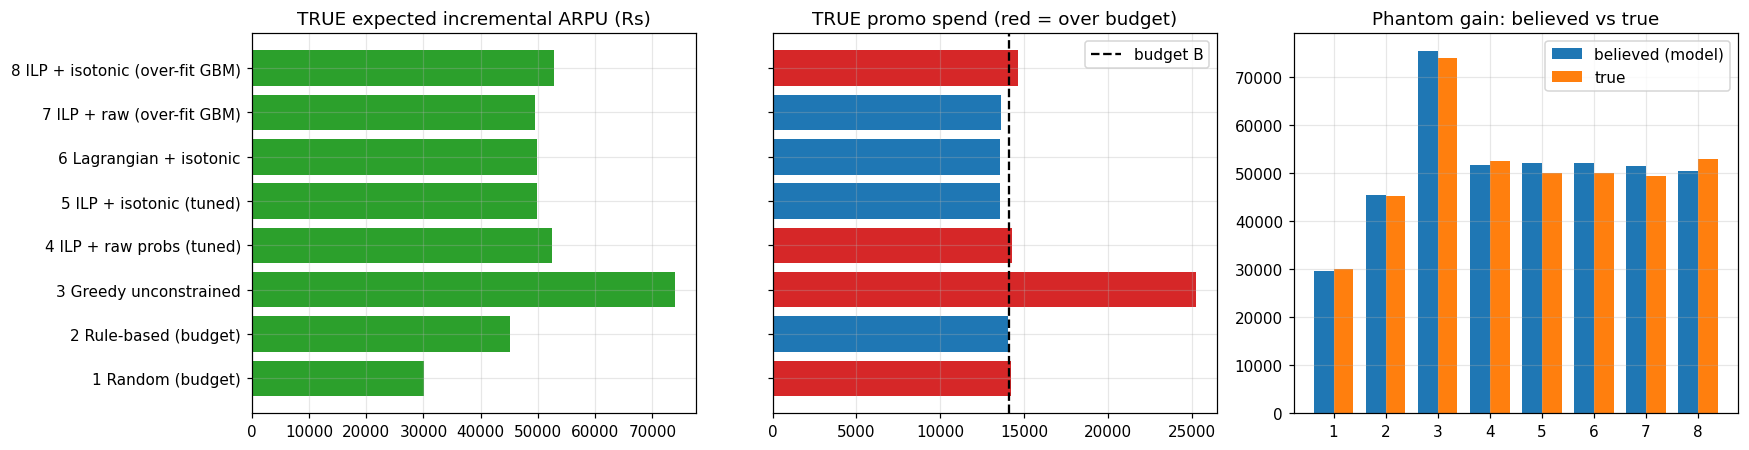

ILP+isotonic vs 1 Random (budget): +65.9% true incremental ARPU
ILP+isotonic vs 2 Rule-based (budget): +10.6% true incremental ARPU


In [42]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].barh(res_tab.index, res_tab["TRUE incr. ARPU (Rs)"], color="tab:green"); ax[0].set_title("TRUE expected incremental ARPU (Rs)")
ax[1].barh(res_tab.index, res_tab["TRUE spend"], color=["tab:red" if not w else "tab:blue" for w in res_tab["within budget?"]])
ax[1].axvline(B, color="k", ls="--", label="budget B"); ax[1].legend(); ax[1].set_title("TRUE promo spend (red = over budget)")
w = 0.38; xx = np.arange(len(res_tab))
ax[2].bar(xx - w / 2, res_tab["believed value"], w, label="believed (model)")
ax[2].bar(xx + w / 2, res_tab["TRUE incr. ARPU (Rs)"], w, label="true")
ax[2].set_xticks(xx); ax[2].set_xticklabels([t[0] for t in res_tab.index]); ax[2].legend(); ax[2].set_title("Phantom gain: believed vs true")
for a in ax[1:2]: a.set_yticklabels([])
plt.tight_layout(); plt.show()

best = res_tab.loc["5 ILP + isotonic (tuned)", "TRUE incr. ARPU (Rs)"]
for nm in ["1 Random (budget)", "2 Rule-based (budget)"]:
    print(f"ILP+isotonic vs {nm}: {100 * (best / res_tab.loc[nm, 'TRUE incr. ARPU (Rs)'] - 1):+.1f}% true incremental ARPU")

In [43]:
# Which offers does the optimiser hand to which kind of user? (sanity check of business logic)
assigned = np.where(Z_ilp.sum(1) > 0, np.array(OFFERS)[Z_ilp.argmax(1)], "None")
prof = X_test.assign(offer=assigned).groupby("offer")[
    ["current_arpu", "quota_exhaust_hrs", "offpeak_ratio", "is_5g_proxy", "addon_count_60d", "contact_fatigue_7d"]].mean()
prof["users"] = pd.Series(assigned).value_counts()
prof.round(2)

,current_arpu,quota_exhaust_hrs,offpeak_ratio,is_5g_proxy,addon_count_60d,contact_fatigue_7d,users
offer,,,,,,,
Data booster,526.52,7.95,0.75,0.19,2.23,0.86,2193
None,287.42,15.86,0.64,0.12,1.05,1.45,5323
Xstream OTT,442.49,10.84,2.51,0.44,1.00,1.16,140


## 12. Results summary, limitations, and how to take this to production

**What to read off the results (check these against your own run)**
* The tuned, early-stopped LightGBM is already nearly calibrated on this data; isotonic then changes little (and may add a bit of step-function noise). For the deliberately over-fit GBM, isotonic calibration clearly reduces Brier/ECE — calibration is a **safety net**, not a guaranteed gain.
* The constrained ILP beats random and rule-based allocation on **true** incremental ARPU while respecting budget, fatigue, sticker-shock and the OTT quota; the unconstrained greedy plan overspends.
* Compare *believed* vs *true* value and *true spend vs B* across rows 4-8. Differences of a few percent between the ILP variants are **within single-run noise** (one seed, one split) — repeat over several seeds before claiming a winner. Even a calibrated plan can slightly exceed the true budget: the optimiser *selects* users whose estimated $p$ is high, so their estimates are biased upward (the "optimiser's curse"). Remedies: a safety margin on $B$, shrinkage of $p$, or a chance-constraint using $\text{Var}=p(1-p)c^2$.
* The robust conclusions are: ILP/Lagrangian ≫ random, rule-based and unconstrained greedy on value-per-rupee, constraints satisfied, and Lagrangian ≈ ILP.
* The Lagrangian solver should land very close to the exact ILP and scale to 10⁶ users in seconds; $\lambda$ is the marginal value of promo budget.

**Limitations (be explicit about these in a viva / interview)**
1. **Propensity ≠ uplift.** $P(\text{buy }k\mid x)$ includes people who would have bought anyway. The right target is the *incremental* effect $\tau_k(x)=P(\text{buy}\mid\text{offer})-P(\text{buy}\mid\text{no offer})$, estimated from randomised holdouts using T-/X-learners, causal forests, or doubly-robust learners; then use $v_{ik}=\tau_k(x_i)(\Delta_k-c_k)-\text{(cannibalisation)}$ in the *same* optimiser.
2. **Static offline optimisation.** Real systems add exploration (contextual bandits / Thompson sampling) to learn about unseen offers and to avoid feedback loops.
3. **Single period.** Multi-day contact policies (fatigue as a state) lead to constrained MDPs / dynamic programming.
4. **Simulated labels.** Replace §4 with real logs; keep a chronological split; monitor calibration drift (re-fit the isotonic map frequently — it is cheap).
5. **Uncertainty.** Use bootstrap/Wilson intervals on ECE and on the value difference; Precision@K on small $K$ is noisy.

**Extensions:** CatBoost with categorical features · per-segment (Mondrian) calibration · conformal prediction intervals on $p_{ik}$ · robust ILP (chance-constrained budget using the variance $p(1-p)c^2$) · Pareto frontier of value vs budget by sweeping $B$ (next cell).

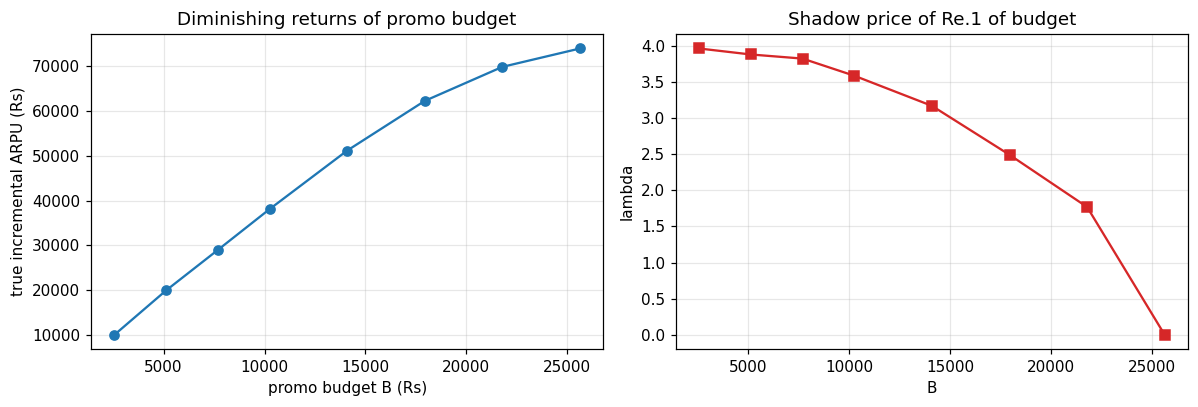

,B/greedy spend,budget,TRUE value,TRUE spend,shadow price lambda
0,0.10,2562.263,10040.172,2494.809,3.962
1,0.20,5124.526,19950.955,5022.528,3.879
2,0.30,7686.789,28980.022,7391.697,3.823
3,0.40,10249.052,38083.931,9876.600,3.585
4,0.55,14092.446,51147.931,13740.807,3.169
5,0.70,17935.841,62234.237,17586.376,2.491
6,0.85,21779.235,69826.234,21240.425,1.769
7,1.00,25622.630,73926.629,25253.201,0.000


In [44]:
# Value-vs-budget frontier: sweep B with the fast Lagrangian solver (calibrated probabilities).
fr = []
for frac in [0.1, 0.2, 0.3, 0.4, 0.55, 0.7, 0.85, 1.0]:
    Bf = frac * greedy_spend
    Zf, lamf, muf = lagrangian_allocate(V_cal, EC_cal, elig, Bf, 0)   # pure budget-value curve (no quota)
    fr.append({"B/greedy spend": frac, "budget": Bf, "TRUE value": (Zf * V_tru).sum(),
               "TRUE spend": (Zf * EC_tru).sum(), "shadow price lambda": lamf})
fr = pd.DataFrame(fr)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(fr["budget"], fr["TRUE value"], "o-"); ax[0].set_xlabel("promo budget B (Rs)"); ax[0].set_ylabel("true incremental ARPU (Rs)")
ax[0].set_title("Diminishing returns of promo budget")
ax[1].plot(fr["budget"], fr["shadow price lambda"], "s-", color="tab:red"); ax[1].set_xlabel("B"); ax[1].set_ylabel("lambda")
ax[1].set_title("Shadow price of Re.1 of budget")
plt.tight_layout(); plt.show()
fr.round(3)